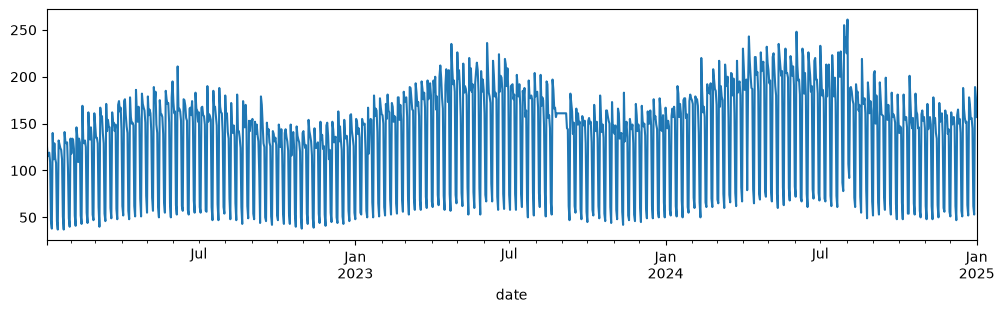

In [37]:
# start here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

s = pd.read_csv(
    "clinic_attendances.csv",
    parse_dates=[0],
    index_col=0
).squeeze("columns")

s.index.freq = "D"

s.plot(figsize=(12, 3))
plt.show()

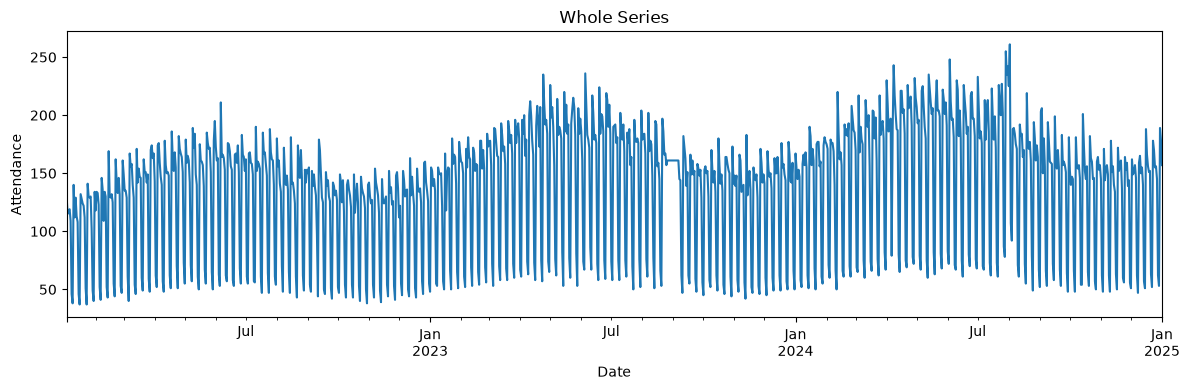

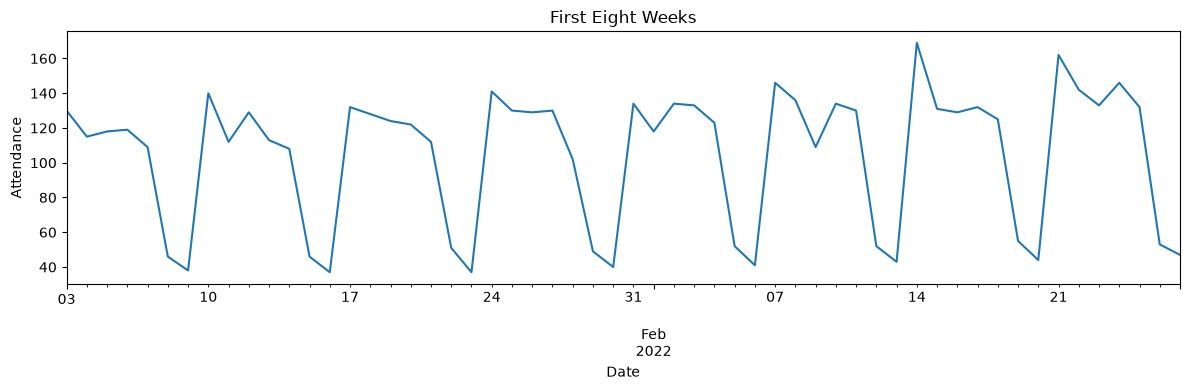

In [38]:
# Create a separate folder for images
image_folder = Path("images")
image_folder.mkdir(exist_ok=True)

# Load the data
s = pd.read_csv(
    "clinic_attendances.csv",
    parse_dates=[0],
    index_col=0
).squeeze("columns")

s.index.freq = "D"

# Plot the whole series
plt.figure(figsize=(12, 4))
s.plot()
plt.title("Whole Series")
plt.xlabel("Date")
plt.ylabel("Attendance")
plt.tight_layout()
plt.savefig(image_folder / "whole_series.png", dpi=300)
plt.show()
plt.close()

# Plot only the first eight weeks (56 days)
first_eight_weeks = s.iloc[:56]

plt.figure(figsize=(12, 4))
first_eight_weeks.plot()
plt.title("First Eight Weeks")
plt.xlabel("Date")
plt.ylabel("Attendance")
plt.tight_layout()
plt.savefig(image_folder / "first_eight_weeks.png", dpi=300)
plt.show()
plt.close()

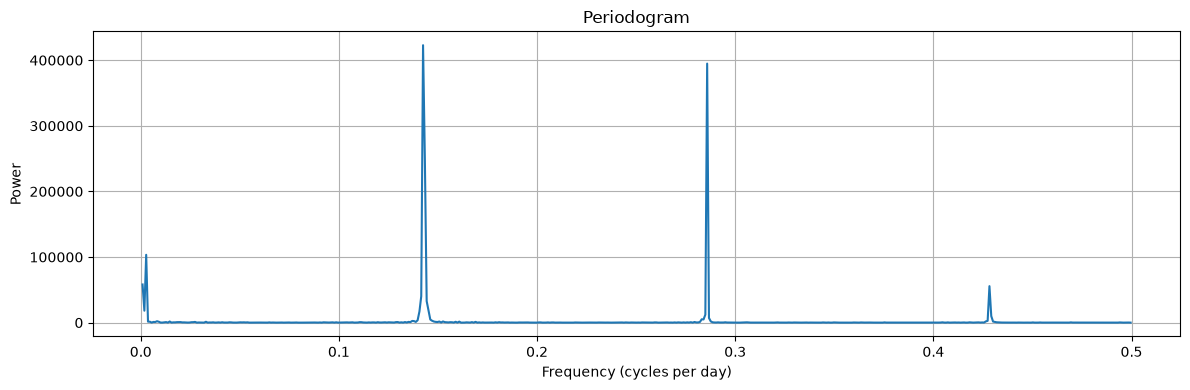

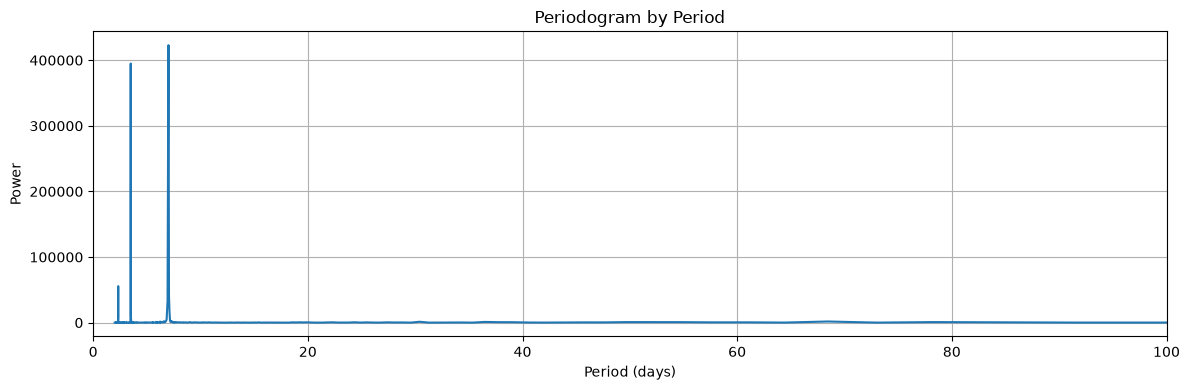

In [39]:
y = s.values.astype(float)

y = y - y.mean()  # remove the mean

power = np.abs(np.fft.rfft(y))**2 / len(y)
freq = np.fft.rfftfreq(len(y), 1.0)

# Remove frequency zero
freq = freq[1:]
power = power[1:]

# Plot power against frequency
plt.figure(figsize=(12, 4))
plt.plot(freq, power)
plt.title("Periodogram")
plt.xlabel("Frequency (cycles per day)")
plt.ylabel("Power")
plt.grid(True)
plt.tight_layout()
plt.savefig("images/periodogram.png", dpi=300)
plt.show()

# Convert frequencies to periods
periods = 1 / freq

# Plot power against period
plt.figure(figsize=(12, 4))
plt.plot(periods, power)
plt.title("Periodogram by Period")
plt.xlabel("Period (days)")
plt.ylabel("Power")
plt.xlim(0, 100)
plt.grid(True)
plt.tight_layout()
plt.savefig("images/periodogram_period.png", dpi=300)
plt.show()

In [40]:
from statsmodels.tsa.seasonal import STL

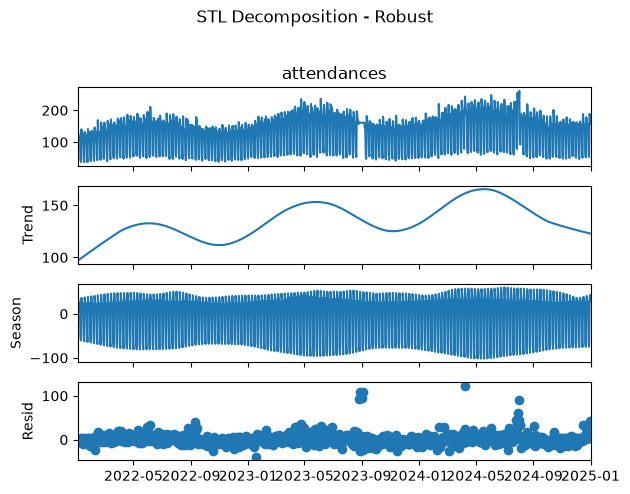

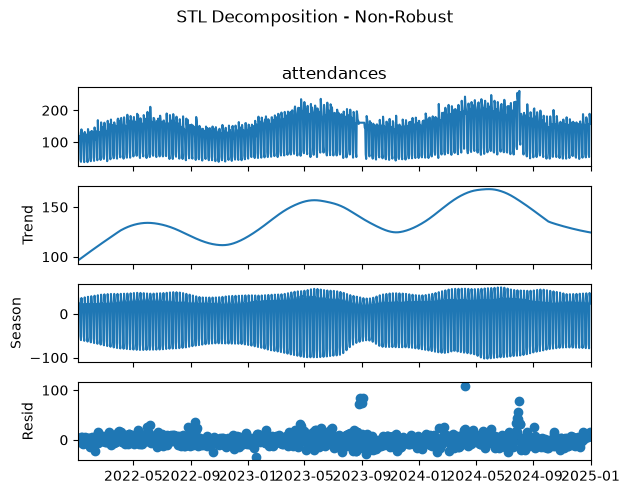

In [41]:
# STL decomposition with robust fitting
res_robust = STL(
    s,
    period=7,
    robust=True,
    seasonal=15,
    trend=181
).fit()

res_robust.plot()
plt.suptitle("STL Decomposition - Robust", y=1.02)
plt.tight_layout()
plt.show()

# STL decomposition without robust fitting
res_nonrobust = STL(
    s,
    period=7,
    robust=False,
    seasonal=15,
    trend=181
).fit()

res_nonrobust.plot()
plt.savefig("images/STL.png", dpi=300)
plt.suptitle("STL Decomposition - Non-Robust", y=1.02)
plt.tight_layout()

In [42]:
import numpy as np
from statsmodels.tsa.seasonal import STL

# Create the STL decomposition
res = STL(
    s,
    period=7,
    robust=True,
    seasonal=15,
    trend=181
).fit()

# Calculate the remainder
rem = s - res.seasonal - res.trend

# Calculate the robust z-score
median_rem = rem.median()
mad = np.median(np.abs(rem - median_rem))

z = (rem - median_rem) / (1.4826 * mad)

# Find anomalies
flagged = s.index[np.abs(z) > 5]

print("Flagged dates:")
for date in flagged:
    print(date)

Flagged dates:
2022-06-06 00:00:00
2022-09-10 00:00:00
2023-01-17 00:00:00
2023-04-21 00:00:00
2023-04-24 00:00:00
2023-08-26 00:00:00
2023-08-27 00:00:00
2023-09-02 00:00:00
2023-09-03 00:00:00
2024-04-07 00:00:00
2024-07-25 00:00:00
2024-07-29 00:00:00
2024-07-30 00:00:00
2024-07-31 00:00:00
2024-08-01 00:00:00
2024-08-02 00:00:00
2024-08-03 00:00:00
2024-12-30 00:00:00


In [43]:
import numpy as np
import pandas as pd

# Calculate the STL remainder
rem = s - res.seasonal - res.trend

# Robust z-score using the median and MAD
rem_median = rem.median()
mad = np.median(np.abs(rem - rem_median))

z = (rem - rem_median) / (1.4826 * mad)

# Four deliberate fault incidents
real_fault_dates = pd.to_datetime([
    "2023-08-26", "2023-08-27", "2023-08-28",
    "2023-09-02", "2023-09-03", "2023-09-04",
    "2024-04-07", "2024-04-08",
    "2024-07-25", "2024-07-26",
    "2024-07-29", "2024-07-30", "2024-07-31",
    "2024-08-01", "2024-08-02", "2024-08-03", "2024-08-04"
])

# Group consecutive dates into incidents
def group_incidents(dates):
    dates = pd.DatetimeIndex(dates).sort_values()

    if len(dates) == 0:
        return []

    incidents = [[dates[0]]]

    for date in dates[1:]:
        if (date - incidents[-1][-1]).days <= 1:
            incidents[-1].append(date)
        else:
            incidents.append([date])

    return incidents


# Results for thresholds 3, 4, 5 and 6
for threshold in [3, 4, 5, 6]:
    flagged = s.index[np.abs(z) > threshold]
    incidents = group_incidents(flagged)

    real_flags = flagged.intersection(real_fault_dates)
    false_alarms = flagged.difference(real_fault_dates)

    print(f"\nTHRESHOLD {threshold}")
    print(f"Total flags: {len(flagged)}")
    print(f"Real flags: {len(real_flags)}")
    print(f"False alarms: {len(false_alarms)}")

    print("\nFlagged incidents:")
    for number, incident in enumerate(incidents, start=1):
        print(
            f"Incident {number}: "
            f"{incident[0].date()} to {incident[-1].date()} "
            f"({len(incident)} flag(s))"
        )


# Compare with ordinary mean and standard deviation
z_ordinary = (rem - rem.mean()) / rem.std()

print("\nCOMPARISON WITH ORDINARY Z-SCORE")

for threshold in [3, 4, 5, 6]:
    robust_flags = s.index[np.abs(z) > threshold]
    ordinary_flags = s.index[np.abs(z_ordinary) > threshold]

    print(f"\nThreshold {threshold}")
    print(f"Robust MAD flags: {len(robust_flags)}")
    print(f"Ordinary mean/std flags: {len(ordinary_flags)}")
    print(f"Difference: {len(robust_flags) - len(ordinary_flags)}")


THRESHOLD 3
Total flags: 60
Real flags: 17
False alarms: 43

Flagged incidents:
Incident 1: 2022-02-09 to 2022-02-09 (1 flag(s))
Incident 2: 2022-05-11 to 2022-05-11 (1 flag(s))
Incident 3: 2022-05-31 to 2022-05-31 (1 flag(s))
Incident 4: 2022-06-06 to 2022-06-06 (1 flag(s))
Incident 5: 2022-08-25 to 2022-08-25 (1 flag(s))
Incident 6: 2022-09-02 to 2022-09-02 (1 flag(s))
Incident 7: 2022-09-10 to 2022-09-10 (1 flag(s))
Incident 8: 2022-09-12 to 2022-09-13 (2 flag(s))
Incident 9: 2022-10-18 to 2022-10-18 (1 flag(s))
Incident 10: 2022-12-01 to 2022-12-01 (1 flag(s))
Incident 11: 2023-01-17 to 2023-01-17 (1 flag(s))
Incident 12: 2023-02-08 to 2023-02-08 (1 flag(s))
Incident 13: 2023-04-11 to 2023-04-11 (1 flag(s))
Incident 14: 2023-04-18 to 2023-04-18 (1 flag(s))
Incident 15: 2023-04-21 to 2023-04-21 (1 flag(s))
Incident 16: 2023-04-24 to 2023-04-25 (2 flag(s))
Incident 17: 2023-05-01 to 2023-05-01 (1 flag(s))
Incident 18: 2023-05-24 to 2023-05-25 (2 flag(s))
Incident 19: 2023-06-05 to 2

ROUTE 1


/var/folders/2b/j_zx0wgx4d33kw7w475hr70r0000gn/T/ipykernel_50456/2003065580.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  return kpss(series, regression="c", nlags="auto")[1]
/var/folders/2b/j_zx0wgx4d33kw7w475hr70r0000gn/T/ipykernel_50456/2003065580.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  return kpss(series, regression="c", nlags="auto")[1]
/var/folders/2b/j_zx0wgx4d33kw7w475hr70r0000gn/T/ipykernel_50456/2003065580.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  return kpss(series, regression="c", nlags="auto")[1]


,Stage,ADF p-value,KPSS p-value,Variance,Lag-1 ACF
0,Raw,2.259522e-01,0.010000,2890.813365,0.348711
1,After log,1.521999e-01,0.094655,0.246685,0.320842
2,After first difference,9.129733e-16,0.100000,0.335344,-0.066346
3,After seasonal difference lag 7,6.136917e-25,0.100000,0.021845,-0.416940


ROUTE 2


/var/folders/2b/j_zx0wgx4d33kw7w475hr70r0000gn/T/ipykernel_50456/2003065580.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  return kpss(series, regression="c", nlags="auto")[1]
/var/folders/2b/j_zx0wgx4d33kw7w475hr70r0000gn/T/ipykernel_50456/2003065580.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  return kpss(series, regression="c", nlags="auto")[1]


,Stage,ADF p-value,KPSS p-value,Variance,Lag-1 ACF
0,Raw,2.259522e-01,0.010000,2890.813365,0.348711
1,After log,1.521999e-01,0.094655,0.246685,0.320842
2,After seasonal difference lag 7,2.335606e-12,0.100000,0.013902,0.214901


First passing stage - Route 1: After first difference
First passing stage - Route 2: After seasonal difference lag 7


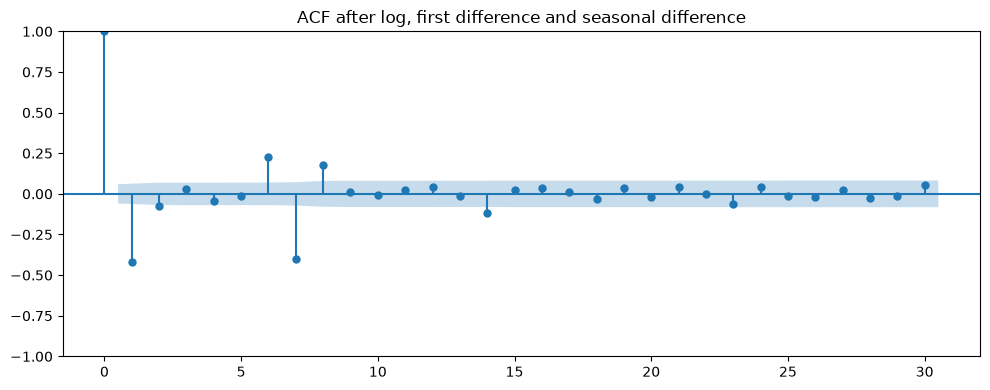

ROUTE COMPARISON


,Route,Variance,Lag-1 ACF
0,Log -> first difference -> seasonal difference,0.021845,-0.416940
1,Log -> seasonal difference,0.013902,0.214901


In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

# -------------------------------------------------
# Helper functions
# -------------------------------------------------

def adf_pvalue(series):
    series = series.dropna()
    return adfuller(series, autolag="AIC")[1]


def kpss_pvalue(series):
    series = series.dropna()
    return kpss(series, regression="c", nlags="auto")[1]


def test_series(name, series):
    series = series.dropna()

    return {
        "Stage": name,
        "ADF p-value": adf_pvalue(series),
        "KPSS p-value": kpss_pvalue(series),
        "Variance": series.var(),
        "Lag-1 ACF": series.autocorr(lag=1)
    }


# -------------------------------------------------
# Route 1: log -> first difference -> seasonal difference
# -------------------------------------------------

log_s = np.log(s)

first_difference = log_s.diff().dropna()

route_1_final = first_difference.diff(7).dropna()

route_1_results = [
    test_series("Raw", s),
    test_series("After log", log_s),
    test_series("After first difference", first_difference),
    test_series("After seasonal difference lag 7", route_1_final)
]

route_1_table = pd.DataFrame(route_1_results)

print("ROUTE 1")
display(route_1_table)


# -------------------------------------------------
# Route 2: log -> seasonal difference
# -------------------------------------------------

route_2_final = log_s.diff(7).dropna()

route_2_results = [
    test_series("Raw", s),
    test_series("After log", log_s),
    test_series("After seasonal difference lag 7", route_2_final)
]

route_2_table = pd.DataFrame(route_2_results)

print("ROUTE 2")
display(route_2_table)


# -------------------------------------------------
# Find the first stage that passes both tests
# ADF: small p-value
# KPSS: large p-value
# -------------------------------------------------

def first_passing_stage(table):
    passed = table[
        (table["ADF p-value"] < 0.05) &
        (table["KPSS p-value"] > 0.05)
    ]

    if len(passed) == 0:
        return "No stage passes both tests"

    return passed.iloc[0]["Stage"]


print("First passing stage - Route 1:",
      first_passing_stage(route_1_table))

print("First passing stage - Route 2:",
      first_passing_stage(route_2_table))


# -------------------------------------------------
# ACF at the first route's final stage
# -------------------------------------------------

plt.figure(figsize=(10, 4))
plot_acf(route_1_final, lags=30, ax=plt.gca())
plt.title("ACF after log, first difference and seasonal difference")
plt.tight_layout()
plt.savefig("images/c5_acf_route1.png", dpi=300)
plt.show()


# -------------------------------------------------
# Compare the two final routes
# -------------------------------------------------

comparison = pd.DataFrame({
    "Route": [
        "Log -> first difference -> seasonal difference",
        "Log -> seasonal difference"
    ],
    "Variance": [
        route_1_final.var(),
        route_2_final.var()
    ],
    "Lag-1 ACF": [
        route_1_final.autocorr(lag=1),
        route_2_final.autocorr(lag=1)
    ]
})

print("ROUTE COMPARISON")
display(comparison)

ROUTE 1


/var/folders/2b/j_zx0wgx4d33kw7w475hr70r0000gn/T/ipykernel_50456/2003065580.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  return kpss(series, regression="c", nlags="auto")[1]
/var/folders/2b/j_zx0wgx4d33kw7w475hr70r0000gn/T/ipykernel_50456/2003065580.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  return kpss(series, regression="c", nlags="auto")[1]
/var/folders/2b/j_zx0wgx4d33kw7w475hr70r0000gn/T/ipykernel_50456/2003065580.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  return kpss(series, regression="c", nlags="auto")[1]


,Stage,ADF p-value,KPSS p-value,Variance,Lag-1 ACF
0,Raw,2.259522e-01,0.010000,2890.813365,0.348711
1,After log,1.521999e-01,0.094655,0.246685,0.320842
2,After first difference,9.129733e-16,0.100000,0.335344,-0.066346
3,After seasonal difference lag 7,6.136917e-25,0.100000,0.021845,-0.416940


ROUTE 2


/var/folders/2b/j_zx0wgx4d33kw7w475hr70r0000gn/T/ipykernel_50456/2003065580.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  return kpss(series, regression="c", nlags="auto")[1]
/var/folders/2b/j_zx0wgx4d33kw7w475hr70r0000gn/T/ipykernel_50456/2003065580.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  return kpss(series, regression="c", nlags="auto")[1]


,Stage,ADF p-value,KPSS p-value,Variance,Lag-1 ACF
0,Raw,2.259522e-01,0.010000,2890.813365,0.348711
1,After log,1.521999e-01,0.094655,0.246685,0.320842
2,After seasonal difference lag 7,2.335606e-12,0.100000,0.013902,0.214901


First passing stage - Route 1: After first difference
First passing stage - Route 2: After seasonal difference lag 7


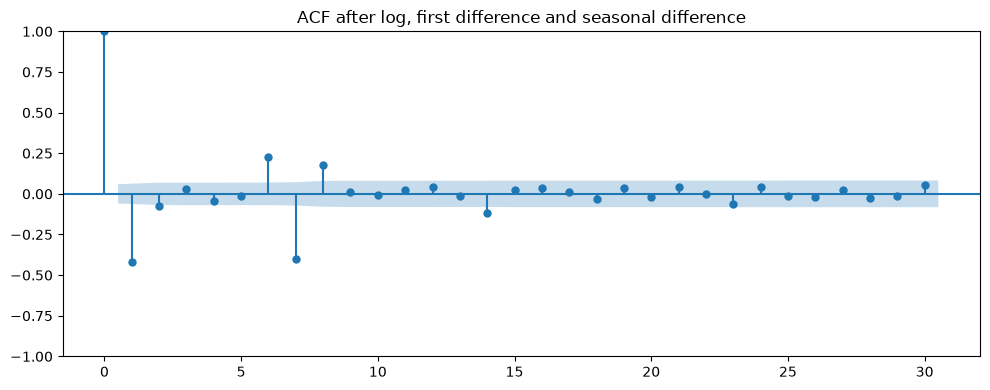

ROUTE COMPARISON


,Route,Variance,Lag-1 ACF
0,Log -> first difference -> seasonal difference,0.021845,-0.416940
1,Log -> seasonal difference,0.013902,0.214901


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

# -------------------------------------------------
# Helper functions
# -------------------------------------------------

def adf_pvalue(series):
    series = series.dropna()
    return adfuller(series, autolag="AIC")[1]


def kpss_pvalue(series):
    series = series.dropna()
    return kpss(series, regression="c", nlags="auto")[1]


def test_series(name, series):
    series = series.dropna()

    return {
        "Stage": name,
        "ADF p-value": adf_pvalue(series),
        "KPSS p-value": kpss_pvalue(series),
        "Variance": series.var(),
        "Lag-1 ACF": series.autocorr(lag=1)
    }


# -------------------------------------------------
# Route 1: log -> first difference -> seasonal difference
# -------------------------------------------------

log_s = np.log(s)

first_difference = log_s.diff().dropna()

route_1_final = first_difference.diff(7).dropna()

route_1_results = [
    test_series("Raw", s),
    test_series("After log", log_s),
    test_series("After first difference", first_difference),
    test_series("After seasonal difference lag 7", route_1_final)
]

route_1_table = pd.DataFrame(route_1_results)

print("ROUTE 1")
display(route_1_table)


# -------------------------------------------------
# Route 2: log -> seasonal difference
# -------------------------------------------------

route_2_final = log_s.diff(7).dropna()

route_2_results = [
    test_series("Raw", s),
    test_series("After log", log_s),
    test_series("After seasonal difference lag 7", route_2_final)
]

route_2_table = pd.DataFrame(route_2_results)

print("ROUTE 2")
display(route_2_table)


# -------------------------------------------------
# Find the first stage that passes both tests
# ADF: small p-value
# KPSS: large p-value
# -------------------------------------------------

def first_passing_stage(table):
    passed = table[
        (table["ADF p-value"] < 0.05) &
        (table["KPSS p-value"] > 0.05)
    ]

    if len(passed) == 0:
        return "No stage passes both tests"

    return passed.iloc[0]["Stage"]


print("First passing stage - Route 1:",
      first_passing_stage(route_1_table))

print("First passing stage - Route 2:",
      first_passing_stage(route_2_table))


# -------------------------------------------------
# ACF at the first route's final stage
# -------------------------------------------------

plt.figure(figsize=(10, 4))
plot_acf(route_1_final, lags=30, ax=plt.gca())
plt.title("ACF after log, first difference and seasonal difference")
plt.tight_layout()
plt.savefig("images/c5_acf_route1.png", dpi=300)
plt.show()


# -------------------------------------------------
# Compare the two final routes
# -------------------------------------------------

comparison = pd.DataFrame({
    "Route": [
        "Log -> first difference -> seasonal difference",
        "Log -> seasonal difference"
    ],
    "Variance": [
        route_1_final.var(),
        route_2_final.var()
    ],
    "Lag-1 ACF": [
        route_1_final.autocorr(lag=1),
        route_2_final.autocorr(lag=1)
    ]
})

print("ROUTE COMPARISON")
display(comparison)